In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
from pandas.core import sample

torch.manual_seed(42)

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch, 'mps') and torch.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

In [3]:
device

device(type='cpu')

In [4]:
sample_tensor = torch.tensor([[1.0,2.0],[3.0,4.0]])
print("Before moving: ", sample_tensor.device)
sample_tensor = sample_tensor.to(device)
print("After moving: ", sample_tensor.device)

Before moving:  cpu
After moving:  cpu


In [5]:
# transforms.ToTensor() + transforms.Normalize()
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

In [6]:
train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform,
)
test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform,
)

In [7]:
len(train_dataset), len(test_dataset)

(60000, 10000)

In [8]:
batch_size = 64
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
)
test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False,
)

In [10]:
len(train_loader), len(test_loader)

(938, 157)

In [11]:
image, label = train_dataset[0]

In [12]:
image.shape

torch.Size([1, 28, 28])

In [13]:
label

5

In [14]:
image.dtype

torch.float32

In [15]:
image.device

device(type='cpu')

In [20]:
def show_mnist_image(image_tensor, label):
     image = image_tensor.squeeze()
     image = image * 0.3081 + 0.1307

     plt.imshow(image, cmap='gray')
     plt.title(f"Label: {label}")
     plt.axis("off")
     plt.show()

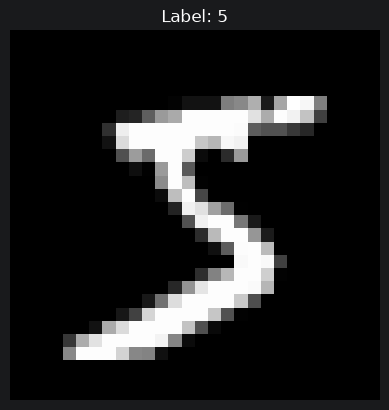

In [21]:
show_mnist_image(image, label)

In [22]:
images, labels = next(iter(train_loader))

In [23]:
images.shape, labels.shape

(torch.Size([64, 1, 28, 28]), torch.Size([64]))

In [24]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.layers(x)
        return x

In [25]:
model = MNISTClassifier().to(device)
print(model)
print("\nModel Device: ", next(model.parameters()).device)

MNISTClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)

Model Device:  cpu


In [27]:
images = images.to(device)
labels = labels.to(device)

logits = model(images)
logits.shape, logits.shape

(torch.Size([64, 10]), torch.Size([64, 10]))

In [29]:
image.shape, logits.shape

(torch.Size([1, 28, 28]), torch.Size([64, 10]))

In [30]:
logits[0]

tensor([ 0.1040,  0.3707,  0.0853, -0.0407, -0.0527, -0.0191,  0.1609, -0.1665,
         0.1527, -0.1726], grad_fn=<SelectBackward0>)

In [31]:
predicted_classes = logits.argmax(dim=1)

In [32]:
predicted_classes[:10]

tensor([1, 8, 8, 8, 8, 8, 8, 8, 8, 8])

In [33]:
labels[:10]

tensor([1, 2, 8, 5, 2, 6, 9, 9, 9, 4])